Loading dataset...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step 
Training samples: 25000
Testing samples: 25000


C:\Users\ADMIN\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling1d             │ ?                           │               0 │
│ (GlobalAveragePooling1D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6734 - loss: 0.6503 - val_accuracy: 0.7152 - val_loss: 0.5691
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8164 - loss: 0.4595 - val_accuracy: 0.8246 - val_loss: 0.4029
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8681 - loss: 0.3386 - val_accuracy: 0.8650 - val_loss: 0.3436

Model Evaluation
Test Accuracy: 84.98%
Test Loss: 0.3561


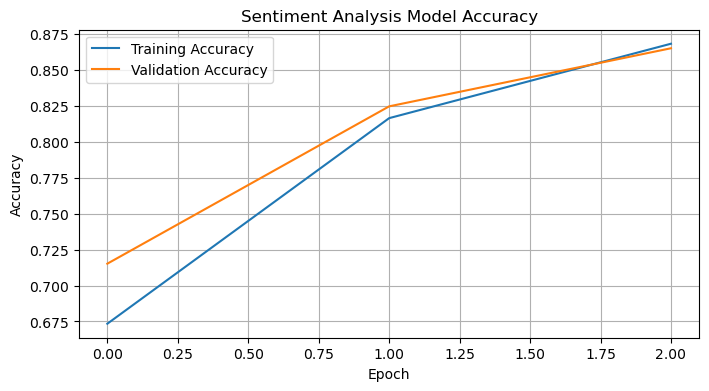

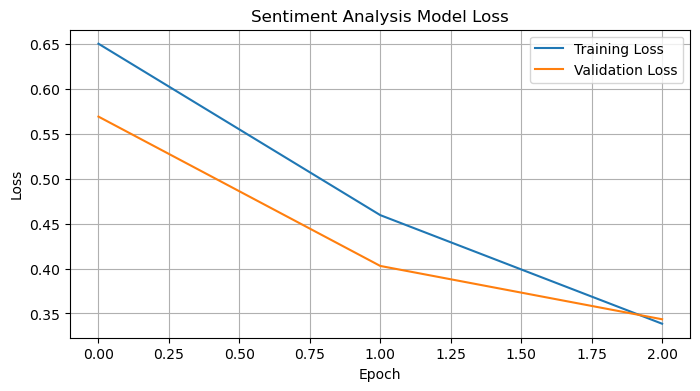

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 2s 1us/step 

Review: This movie was amazing and I really enjoyed it
Predicted sentiment: Positive
Positive probability: 65.47%

Review: This movie was boring and I hated it
Predicted sentiment: Negative
Positive probability: 36.99%

Review: The story was wonderful and the acting was excellent
Predicted sentiment: Positive
Positive probability: 63.86%

Project completed!
Model saved as sentiment_analysis_model.keras


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

# 1. Loading dataset
print("Loading dataset...")

vocab_size = 10000
max_length = 200

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# 2. Preparing the data
X_train = pad_sequences(
    X_train, maxlen=max_length, padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test, maxlen=max_length, padding="post", truncating="post"
)

# 3. Building the AI model
model = Sequential([
    Embedding(vocab_size, 32, input_length=max_length),
    GlobalAveragePooling1D(),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

# 4. Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=3,
    batch_size=128,
    validation_split=0.2
)

# 6. Evaluate the model
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("\nModel Evaluation")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# 7. Plot training and validation accuracy
plt.figure(figsize=(8, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Sentiment Analysis Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 8. Plot training and validation loss
plt.figure(figsize=(8, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Sentiment Analysis Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 9. Convert words into the format that is used by the IMDB dataset
word_index = imdb.get_word_index()

word_index = {
    word: index + 3 for word, index in word_index.items()
}
word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3

def encode_review(text):
    words = text.lower().split()
    sequence = [1]

    for word in words:
        sequence.append(word_index.get(word, 2))

    return pad_sequences(
        [sequence],
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

# 10. Test the model with your own sentences
def predict_sentiment(text):
    encoded = encode_review(text)
    probability = float(model.predict(encoded, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("\nReview:", text)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability * 100:.2f}%")

predict_sentiment("This movie was amazing and I really enjoyed it")
predict_sentiment("This movie was boring and I hated it")
predict_sentiment("The story was wonderful and the acting was excellent")

# 11. Save the trained model
model.save("sentiment_analysis_model.keras")
